## 0. Package loading

In [28]:
from datasets import load_dataset
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.metrics import classification_report, accuracy_score, f1_score
import re
from collections import Counter
import numpy as np
import scipy.sparse as sp
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedShuffleSplit

## 1. Dataset loading

Dataset is obtained from https://huggingface.co/datasets/jcblaise/fake_news_filipino.

The dataset contains two columns. The first column is the label, which is either 0 or 1. 0 corresponds to real while 1 corresponds to fake. The second column is the article itself.

In [21]:
df = pd.read_csv("/kaggle/input/datasets/ivancobarrubias/fake-news-filipino/full.csv")
print(df.shape)
print(df.columns.tolist())  
print(df.head())
print(df["label"].value_counts())
print(df["article"].str.split().str.len().describe())

(3206, 2)
['label', 'article']
   label                                            article
0      0  Ayon sa TheWrap.com, naghain ng kaso si Krupa,...
1      0  Kilala rin ang singer sa pagkumpas ng kanyang ...
2      0  BLANTYRE, Malawi (AP) -- Bumiyahe patungong Ma...
3      0  Kasama sa programa ang pananalangin, bulaklak ...
4      0  Linisin ang Friendship Department dahil dadala...
label
0    1603
1    1603
Name: count, dtype: int64
count    3206.000000
mean      182.726450
std       122.665598
min         8.000000
25%        72.000000
50%       174.000000
75%       265.000000
max      1074.000000
Name: article, dtype: float64


## 2. Baseline: TF-IDF + Linear SVM

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    df["article"], df["label"],
    test_size=0.2, random_state=42, stratify=df["label"]
)

tfidf = TfidfVectorizer(lowercase=True, max_features=20000, ngram_range=(1, 1))
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)

clf = LinearSVC(C=1.0)
clf.fit(Xtr, y_train)

pred = clf.predict(Xte)
print(classification_report(y_test, pred, target_names=["real", "fake"]))

results = {}
results["Baseline TF-IDF + SVM"] = {
    "accuracy": accuracy_score(y_test, pred),
    "macro_f1": f1_score(y_test, pred, average="macro"),
}

              precision    recall  f1-score   support

        real       0.95      0.97      0.96       321
        fake       0.97      0.95      0.96       321

    accuracy                           0.96       642
   macro avg       0.96      0.96      0.96       642
weighted avg       0.96      0.96      0.96       642



The baseline performs well and evenly across both classes: it recovers 97% of real articles and 95% of fake ones, with no strong bias toward either. Because the test set is perfectly balanced, accuracy is a fair headline metric.

Since the baseline results are already relatively high, there is little headroom for the custom kernel. This is likely due to other factors such as writing style, events covered, and formatting. The custom kernel will therefore be evaluated both on full data and with reduced training sizes, where sharing information across related word forms is most likely to help.

## 3. Tagalog Root-Finder (Stemmer)

Standard TF-IDF treats related Tagalog word forms (e.g., *sulat*, *sumulat*, *pagsusulat*) as unrelated features. This step builds a rule-based root-finder that maps such forms to a shared root

In [23]:
VOWELS = set("aeiou")

PREFIXES = sorted(set([
    "nakapag", "makapag", "ipinang", "ipinag", "ipapag", "ikapag", "pinaka", "napaka",
    "pinag", "nagpa", "magpa", "ipang", "ipag", "mapag", "maka", "naka", "mapa", "napa",
    "maki", "naki", "mang", "nang", "pang", "taga", "mag", "nag", "pag", "tag", "ipa",
    "ika", "ka", "ma", "na", "pa", "i",
]), key=len, reverse=True)

SUFFIXES = ["han", "hin", "an", "in"]


def tokenize(text):
    toks = re.findall(r"[a-zñ]+(?:-[a-zñ]+)*", text.lower())
    # sets letters to lowercase, removes hyphens and combines the word
    return [t.replace("-", "") for t in toks]
   


def _starts_ok(r):
    # a valid Tagalog root most likely starts with a vowel (V) or consonant+vowel(CV)
    return len(r) >= 2 and (r[0] in VOWELS or r[1] in VOWELS)


def _strip_prefixes(w):
    out = set()
    for p in PREFIXES:
        if w.startswith(p):
            r = w[len(p):]
            min_len = 4 if len(p) <= 2 else 3   # short prefixes need a longer leftover
            if len(r) >= min_len and _starts_ok(r):
                out.add(r)
    return out


def _strip_infix(w):
    # sulat -> s-um-ulat / s-in-ulat. Only removed if a vowel follows (avoids 'ginto').
    m = re.match(r"^([^aeiouñ])(um|in)([aeiou].*)$", w)
    if m and len(m.group(1) + m.group(3)) >= 3:
        return {m.group(1) + m.group(3)}
    m = re.match(r"^(um|in)([aeiou].*)$", w)   # vowel-initial roots: umalis -> alis
    if m and len(m.group(2)) >= 3:
        return {m.group(2)}
    return set()


def _strip_reduplication(w):
    # susulat -> sulat (repeated first CV), aaral -> aral (repeated first vowel)
    out = set()
    if len(w) >= 5 and w[0] not in VOWELS and w[1] in VOWELS and w[2:4] == w[:2]:
        out.add(w[2:])
    if len(w) >= 4 and w[0] in VOWELS and w[1] == w[0]:
        out.add(w[1:])
    return out


def _strip_suffix(w):
    out = set()
    for s in SUFFIXES:
        if w.endswith(s) and len(w) - len(s) >= 4:
            if s in ("han", "hin") and w[-len(s) - 1] not in VOWELS:
                continue
            out.add(w[:-len(s)])
    return out


def _strip_linker(w):
    # magandang -> maganda (only after a/o/u, so English '-ing' words are untouched)
    if w.endswith("ng") and len(w) >= 6 and w[-3] in "aou":
        return {w[:-2]}
    return set()


def candidates(word):
    cands = {word}
    for stage in (_strip_linker, _strip_prefixes, _strip_prefixes,
                  _strip_infix, _strip_reduplication, _strip_suffix):
        for c in list(cands):
            cands |= stage(c)
    cands.discard(word)
    return cands


class TagalogStemmer:

    def __init__(self, min_freq=2):
        self.min_freq = min_freq
        self.freq = Counter()
        self.family = Counter()
        self.cache = {}

    def fit(self, texts):
        self.freq = Counter(t for text in texts for t in tokenize(text))
        self.family = Counter()
        self.cache = {}
        for w in self.freq:
            if len(w) > 3:
                for c in candidates(w):
                    if self.freq[c] >= self.min_freq:
                        self.family[c] += 1
        return self

    def _stem_once(self, word):
        if len(word) <= 3:
            return word
        good = [c for c in candidates(word) if self.freq[c] >= self.min_freq]
        if not good:
            return word
        return max(good, key=lambda c: (self.family[c], self.freq[c], -len(c)))

    def stem(self, word):
        if word in self.cache:
            return self.cache[word]
        root = word
        for _ in range(3):              # re-stem until stable: magandang -> maganda -> ganda
            nxt = self._stem_once(root)
            if nxt == root:
                break
            root = nxt
        self.cache[word] = root
        return root

    def stem_text(self, text):
        return " ".join(self.stem(t) for t in tokenize(text))


# Fit on TRAIN only, then sanity-check
stemmer = TagalogStemmer().fit(X_train)

for w in ["sulat", "sumulat", "sinulat", "isulat", "susulat", "pagsusulat", "nagsusulat"]:
    print(f"{w:12s} -> {stemmer.stem(w)}")

sulat        -> sulat
sumulat      -> sulat
sinulat      -> sulat
isulat       -> sulat
susulat      -> sulat
pagsusulat   -> sulat
nagsusulat   -> sulat


## 4. Kernel Construction

The kernel follows the **soft cosine measure** (Sidorov et al., 2014), which extends cosine similarity so that similar (not just identical) features contribute to the similarity of two documents. When no features are similar, it reduces to the standard cosine similarity.

For two articles a and b (TF-IDF vectors), the kernel is K(a, b) = aᵀSb, cosine-normalized, where S = (1 − α)I + αR. Here, I is the identity matrix (a word is only similar to itself, as in the baseline) and R[i, j] = 1 if words i and j share a root according to the Step 4 root-finder, and 0 otherwise. The parameter α controls the blend: α = 0 recovers the baseline TF-IDF kernel and α = 1 uses root-matching only.


In [25]:
words = tfidf.get_feature_names_out()
roots = [stemmer.stem(w) for w in words]
root_ids = {r: i for i, r in enumerate(sorted(set(roots)))}
M = sp.csr_matrix(
    (np.ones(len(words)), (np.arange(len(words)), [root_ids[r] for r in roots])),
    shape=(len(words), len(root_ids)),
)
print("words:", len(words), "-> roots:", len(root_ids))

def soft_kernel(A, B, M, alpha):
    """K(a,b) = a^T [(1-alpha) I + alpha R] b, cosine-normalized."""
    AM, BM = A @ M, B @ M
    K = ((1 - alpha) * (A @ B.T) + alpha * (AM @ BM.T)).toarray()
    da = (1 - alpha) * np.asarray(A.multiply(A).sum(1)).ravel() + alpha * np.asarray(AM.multiply(AM).sum(1)).ravel()
    db = (1 - alpha) * np.asarray(B.multiply(B).sum(1)).ravel() + alpha * np.asarray(BM.multiply(BM).sum(1)).ravel()
    return K / np.sqrt(np.outer(da, db))

# Tune C by 5-fold Cross Validation on TRAIN only, for each alpha; then score once on test
for alpha in [0.0, 0.25, 0.5, 0.75, 1.0]:
    Ktr = soft_kernel(Xtr, Xtr, M, alpha)
    gs = GridSearchCV(SVC(kernel="precomputed"), {"C": [0.1, 1, 10, 100]}, cv=5).fit(Ktr, y_train)
    pred = gs.predict(soft_kernel(Xte, Xtr, M, alpha))
    results[f"Custom kernel (alpha={alpha})"] = {
        "accuracy": accuracy_score(y_test, pred),
        "macro_f1": f1_score(y_test, pred, average="macro"),
        "cv_accuracy": gs.best_score_,
    }
    print(f"alpha={alpha}: C={gs.best_params_['C']}, cv={gs.best_score_:.4f}, test={results[f'Custom kernel (alpha={alpha})']['accuracy']:.4f}")

words: 20000 -> roots: 16108
alpha=0.0: C=10, cv=0.9544, test=0.9595
alpha=0.25: C=10, cv=0.9528, test=0.9533
alpha=0.5: C=10, cv=0.9513, test=0.9548
alpha=0.75: C=10, cv=0.9493, test=0.9548
alpha=1.0: C=10, cv=0.9450, test=0.9486


## 5. Soft Kernel Validity Check

In [27]:
for alpha in [0.0, 0.25, 0.5, 0.75, 1.0]:
    K = soft_kernel(Xtr, Xtr, M, alpha)
    ev = np.linalg.eigvalsh(K)
    print(f"alpha={alpha}: symmetric={np.allclose(K, K.T)}, "
          f"min eigenvalue={ev.min():.2e}, PSD={ev.min() >= -1e-8 * ev.max()}")


alpha=0.0: symmetric=True, min eigenvalue=-3.28e-15, PSD=True
alpha=0.25: symmetric=True, min eigenvalue=-4.89e-15, PSD=True
alpha=0.5: symmetric=True, min eigenvalue=-2.60e-15, PSD=True
alpha=0.75: symmetric=True, min eigenvalue=-2.29e-15, PSD=True
alpha=1.0: symmetric=True, min eigenvalue=-3.12e-15, PSD=True


**Result:** For every α ∈ {0, 0.25, 0.5, 0.75, 1.0}, the training Gram matrix (n = 2,564) was symmetric and positive semi-definite (minimum eigenvalue ≈ −3×10⁻¹⁵, within floating-point rounding of zero), so the kernel is valid for use with the SVM.

## 6. Results and Discussion

In [29]:
table = pd.DataFrame(results).T.round(4)
table.index.name = "Model"
table

,accuracy,macro_f1,cv_accuracy
Model,,,
Baseline TF-IDF + SVM,0.9595,0.9595,NaN
Custom kernel (alpha=0.0),0.9595,0.9595,0.9544
Custom kernel (alpha=0.25),0.9533,0.9533,0.9528
Custom kernel (alpha=0.5),0.9548,0.9548,0.9513
Custom kernel (alpha=0.75),0.9548,0.9548,0.9493
Custom kernel (alpha=1.0),0.9486,0.9486,0.9450


C was tuned by 5-fold cross-validation on the training split only; the test set (n = 642) was scored once per model. The α = 0 kernel reproduces the baseline, as expected.

To test whether root-matching helps when labeled data is scarce, models were trained on random stratified subsets of the training split (3%, 5%, 10%, 25%, 50%, and 100%, i.e., 76 to 2,564 articles) and evaluated on the same held-out test set (n = 642). Each size was repeated with 5 random subsets (the full-data point is a single run, so it has no error bar). C was fixed at 10, the value selected by cross-validation in the main comparison, so it was not retuned at each size. Three settings of the kernel are shown: α = 0 (plain TF-IDF), α = 0.5 (blend), and α = 1 (roots only).


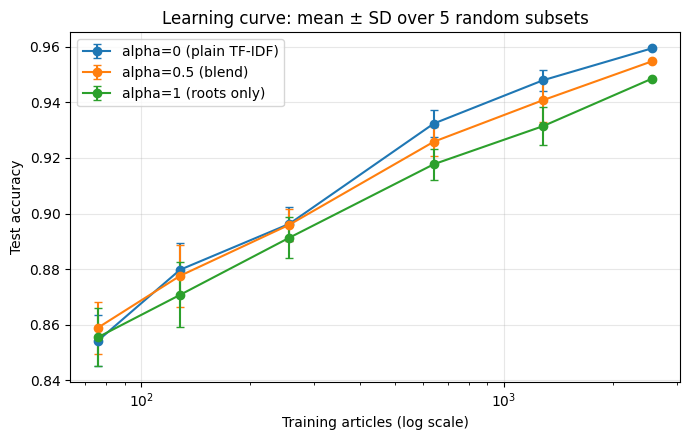

In [30]:
fractions = [0.03, 0.05, 0.10, 0.25, 0.50, 1.0]
alphas_lc = [0.0, 0.5, 1.0]
n_seeds, C_fixed = 5, 10
curve = {a: [] for a in alphas_lc}

for frac in fractions:
    scores = {a: [] for a in alphas_lc}
    for seed in range(n_seeds):
        if frac < 1.0:
            idx = next(StratifiedShuffleSplit(1, train_size=frac, random_state=seed).split(Xtr, y_train))[0]
        else:
            idx = np.arange(Xtr.shape[0])
        A, yy = Xtr[idx], y_train.values[idx]
        for a in alphas_lc:
            clf_a = SVC(kernel="precomputed", C=C_fixed).fit(soft_kernel(A, A, M, a), yy)
            scores[a].append(accuracy_score(y_test, clf_a.predict(soft_kernel(Xte, A, M, a))))
    for a in alphas_lc:
        curve[a].append((np.mean(scores[a]), np.std(scores[a])))

n_train = [int(f * Xtr.shape[0]) for f in fractions]
labels = {0.0: "alpha=0 (plain TF-IDF)", 0.5: "alpha=0.5 (blend)", 1.0: "alpha=1 (roots only)"}

plt.figure(figsize=(7, 4.5))
for a in alphas_lc:
    m = np.array([c[0] for c in curve[a]])
    s = np.array([c[1] for c in curve[a]])
    plt.errorbar(n_train, m, yerr=s, marker="o", capsize=3, label=labels[a])
plt.xscale("log")
plt.xlabel("Training articles (log scale)")
plt.ylabel("Test accuracy")
plt.title("Learning curve: mean ± SD over 5 random subsets")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

*Figure: Test accuracy vs. number of training articles (log scale); points are means over 5 random subsets and error bars show ±1 SD. α = 0 is the plain TF-IDF kernel; α = 1 treats all words with a shared root as identical; α = 0.5 ("blend") weights exact-word and shared-root matches equally.*

**Reading the curve.** All three models improve steadily as training data grows, from roughly 0.85 accuracy at 76 articles to roughly 0.95 to 0.96 at 2,564 articles. At the smallest size, the blend (about 0.859) is marginally ahead of plain TF-IDF (about 0.854), but the gap is smaller than the variation across subsets (SD ≈ 0.01), so it cannot be distinguished from chance. From 128 articles onward, plain TF-IDF is equal to or better than the other settings, and the gap widens with more data: at 2,564 articles the accuracies are 0.9595 (α = 0), 0.9548 (α = 0.5), and 0.9486 (α = 1). The roots-only kernel is the lowest at nearly every size.

**Interpretation.** The hypothesis was that sharing information across related word forms would help most when training data is limited. The curve does not show this: there is no size at which root-matching gives a clear advantage. This is consistent with the main comparison and with the explanations discussed below, none of which were tested here.

### Discussion

**The custom kernel did not outperform the baseline.** On the full training set, test accuracy decreased as the weight on root-matching increased, from 0.9595 at α = 0 (plain TF-IDF) to 0.9486 at α = 1 (roots only), with the blends in between (0.9533 to 0.9548). The cross-validation scores show the same ordering (0.9544 down to 0.9450). In the learning curve, the blended kernel was marginally ahead only at the smallest training size, by less than the variation across subsets, and plain TF-IDF was equal or better at every larger size. The results therefore do not support the hypothesis that treating Tagalog words with a shared root as similar improves fake news detection on this dataset, either with the full training set or when training data is limited.
